#### Import libraries

In [8]:
from ultralytics import YOLO
from collections import Counter
import cv2
import os
import pandas as pd
import matplotlib.pyplot as plt

#### Load Model

In [ ]:
model = YOLO(r"C:\Users\shrav\Desktop\projects\Smart_Factory_ai_monitoring_system\models\best.pt")

print("Model Loaded")

Model Loaded


#### - Select Image

In [17]:
image_path = "../dataset/test/images/" + os.listdir("../dataset/test/images")[5]

image = cv2.imread(image_path)

results = model(image)


0: 416x416 2 Hardhats, 5 NO-Masks, 2 NO-Safety Vests, 3 Persons, 2 Safety Vests, 100.4ms
Speed: 2.6ms preprocess, 100.4ms inference, 6.1ms postprocess per image at shape (1, 3, 416, 416)


#### - Count objects

In [18]:
counter = Counter()

for box in results[0].boxes:

    class_name = model.names[int(box.cls)]

    counter[class_name] += 1

counter

Counter({'NO-Mask': 5,
         'Person': 3,
         'Hardhat': 2,
         'NO-Safety Vest': 2,
         'Safety Vest': 2})

#### - Prepare Dashboard data

In [19]:
workers = counter["Person"]

helmets = counter["Hardhat"]

vests = counter["Safety Vest"]

vehicles = counter["vehicle"]

machines = counter["machinery"]

helmet_violation = max(0, workers - helmets)

vest_violation = max(0, workers - vests)

#### - Create Dataframe

In [20]:
df = pd.DataFrame({

    "Category":[

        "Workers",

        "Helmets",

        "Safety Vest",

        "Vehicles",

        "Machinery",

        "Helmet Violation",

        "Vest Violation"

    ],

    "Count":[

        workers,

        helmets,

        vests,

        vehicles,

        machines,

        helmet_violation,

        vest_violation

    ]

})

df

,Category,Count
0,Workers,3
1,Helmets,2
2,Safety Vest,2
3,Vehicles,0
4,Machinery,0
5,Helmet Violation,1
6,Vest Violation,1


#### - Bar chart

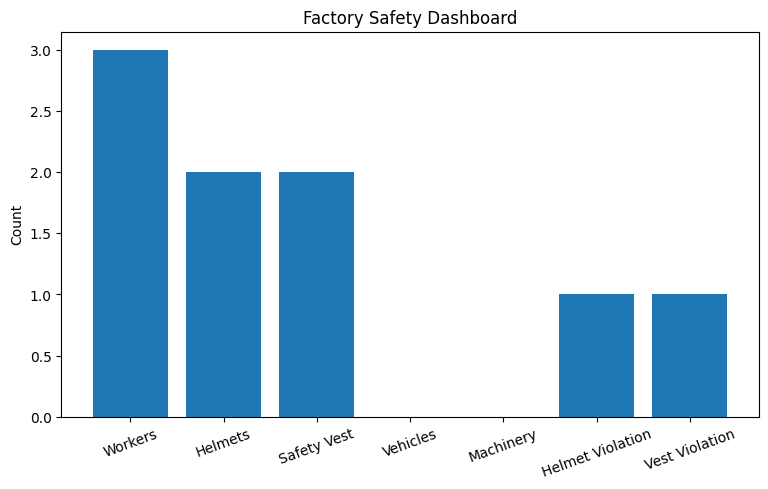

In [21]:
plt.figure(figsize=(9,5))

plt.bar(df["Category"],df["Count"])

plt.xticks(rotation=20)

plt.title("Factory Safety Dashboard")

plt.ylabel("Count")

plt.show()

#### - Pie chart

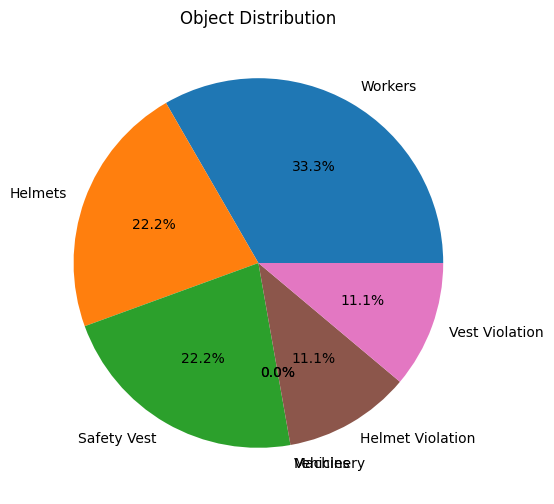

In [22]:
plt.figure(figsize=(6,6))

plt.pie(

    df["Count"],

    labels=df["Category"],

    autopct="%1.1f%%"

)

plt.title("Object Distribution")

plt.show()

#### - Detection Summary

In [23]:
print("="*40)

print("SMART FACTORY REPORT")

print("="*40)

for i in range(len(df)):

    print(

        f"{df.iloc[i,0]:<20}"

        f"{df.iloc[i,1]}"

    )

SMART FACTORY REPORT
Workers             3
Helmets             2
Safety Vest         2
Vehicles            0
Machinery           0
Helmet Violation    1
Vest Violation      1


#### - Display Prediction Image

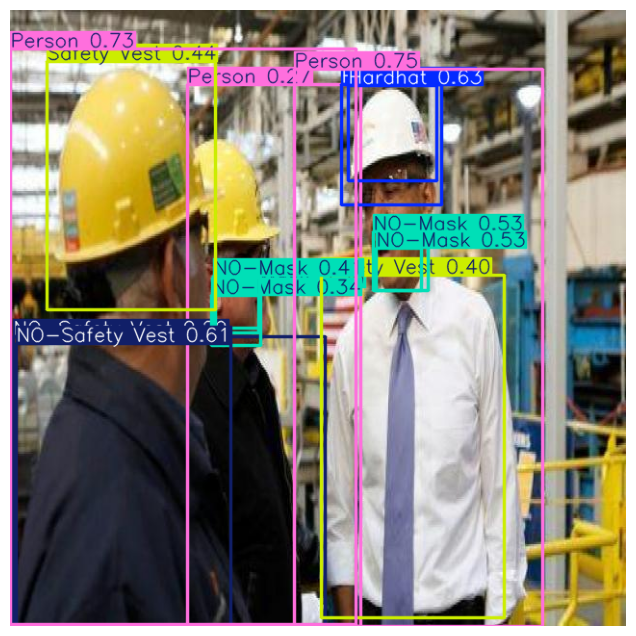

In [24]:
frame = results[0].plot()

frame = cv2.cvtColor(frame,cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12,8))

plt.imshow(frame)

plt.axis("off")

plt.show()

#### - Save Prediciton

In [25]:
import os

os.makedirs("output/images",exist_ok=True)

cv2.imwrite(

    "output/images/dashboard_prediction.jpg",

    cv2.cvtColor(frame,cv2.COLOR_RGB2BGR)

)

print("Image Saved")

Image Saved
